# Week 7: A Minimal RAG Pipeline, Step by Step

<a href="https://colab.research.google.com/github/jorshimayor/AI-Engineering-Flow_Research/blob/main/jupyter/week7_rag_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Retrieval-augmented generation (RAG)** answers a question in two moves: find the passages that contain the answer, then let a language model read them and reply. This notebook builds every piece from scratch, shows what each one does on real examples, and then measures the whole pipeline.

```
 documents ──► chunks ──► index (BM25 / embeddings)
                               │
 question ─────────────────────┴──► top k chunks ──► prompt ──► LLM ──► answer ──► score
```

| | |
|---|---|
| Paper | [Lewis et al., 2020](https://arxiv.org/abs/2005.11401): retrieval beats closed-book on knowledge questions, and swapping the index updates what the model knows |
| Documents | 60 pages about **fictional** products, so the model cannot answer from memory |
| Models | Qwen2.5-1.5B-Instruct and 3B-Instruct; embeddings from bge-small-en-v1.5 |
| Plan and hypotheses | Fixed before this run: [`notes/week_7/README.md`](https://github.com/jorshimayor/AI-Engineering-Flow_Research/blob/main/notes/week_7/README.md) |
| Code | [`src/rag_corpus.py`](https://github.com/jorshimayor/AI-Engineering-Flow_Research/blob/main/src/rag_corpus.py) · [`src/rag.py`](https://github.com/jorshimayor/AI-Engineering-Flow_Research/blob/main/src/rag.py) · [`src/run_rag_bench.py`](https://github.com/jorshimayor/AI-Engineering-Flow_Research/blob/main/src/run_rag_bench.py) |

**How to read this notebook.** The committed copy was executed on a laptop without a GPU. Everything before the model runs (documents, chunking, BM25 retrieval, prompts, scoring) shows real output; the dense-retrieval and model cells say they need a GPU. Once the test run is done, the results sections read the saved files in `results/week7/`.

**Run:** `Runtime → Change runtime type → T4 GPU`, then `Runtime → Run all`. About 30 minutes. Results save to Google Drive after every batch, so a re-run after a disconnect continues where it stopped. At the end the notebook saves a copy of itself **with all outputs**, so the results, tables and graphs stay readable on GitHub.

## 0. Setup

In [1]:
import os, sys
from pathlib import Path
ON_COLAB = "google.colab" in sys.modules
try:
    import torch
    GPU = torch.cuda.is_available()
except ImportError:
    GPU = False
print("Colab:", ON_COLAB, "| GPU:", torch.cuda.get_device_name(0) if GPU else "none, so the model cells are skipped")

Colab: False | GPU: none, so the model cells are skipped


In [2]:
REPO = "https://github.com/jorshimayor/AI-Engineering-Flow_Research.git"
BRANCH = "main"
if ON_COLAB:   # always the latest code
    BASE = "/content"
    CODE = os.path.join(BASE, "AI-Engineering-Flow_Research")
    if not os.path.exists(CODE):
        !git clone --depth 1 --branch {BRANCH} {REPO} {CODE}
    %cd {CODE}
    !git fetch -q --depth 1 origin {BRANCH} && git checkout -q -B {BRANCH} FETCH_HEAD
    !pip install -q "transformers==4.49.0" accelerate
else:          # a local checkout: run from the repo root
    if Path.cwd().name == "jupyter":
        os.chdir("..")
    BASE = os.getcwd()
!git log --oneline --no-color -1

174467a (HEAD -> rich-notebooks, origin/week7-rag, week7-rag) docs(week7): plan and hypotheses fixed before the test run


In [3]:
USE_DRIVE = ON_COLAB
RESULTS = "results/week7"
if USE_DRIVE:
    import shutil
    from google.colab import drive
    drive.mount("/content/drive")
    target = "/content/drive/MyDrive/AI-Engineering/week7"
    os.makedirs(target, exist_ok=True)
    if os.path.isdir(RESULTS) and not os.path.islink(RESULTS):   # keep files the repo already has here
        for f in os.listdir(RESULTS):
            if os.path.isfile(os.path.join(RESULTS, f)) and not os.path.exists(os.path.join(target, f)):
                shutil.copy(os.path.join(RESULTS, f), target)
        shutil.rmtree(RESULTS)
    os.makedirs(os.path.dirname(RESULTS), exist_ok=True)
    if not os.path.islink(RESULTS):
        os.symlink(target, RESULTS)
os.makedirs(RESULTS, exist_ok=True)
print("results go to:", os.path.realpath(RESULTS))

results go to: results/week7


In [4]:
import importlib, inspect, json
sys.path.insert(0, "src")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Code, Image, Markdown, display
import rag_corpus, rag, run_rag_bench, figures
for m in (rag_corpus, rag, run_rag_bench, figures): importlib.reload(m)
%matplotlib inline
assert (rag_corpus.CORPUS_VERSION, rag.RAG_VERSION) == ("1.0", "1.0"), "stale code: Runtime → Disconnect and delete runtime, then Run all"
pd.set_option("display.max_colwidth", 120)

def show(fn):
    """Print a function's source from the repo, so the notebook shows the exact code that runs."""
    display(Code(inspect.getsource(fn), language="python"))

## 1. The documents

Every product, brand, town and number is invented, so the closed-book model has nothing to recall. The four models in a family share almost all their wording and differ in the numbers. That is the trap for retrieval: the C-100, C-200, C-300 and C-400 pages look nearly the same.

In [5]:
DOCS = rag_corpus.build_corpus()
print(len(DOCS), "pages,", sum(d["split"] == "test" for d in DOCS), "of them about test products")
pd.DataFrame([{"doc_id": d["doc_id"], "name": d["name"], "type": d["product_type"], "split": d["split"],
               "words": len(d["text"].split()), **d["values"]} for d in DOCS]).head(8)

60 pages, 48 of them about test products


,doc_id,name,type,split,words,year,town,weight,watts,colour,price,warranty
0,A-100,Aldric A-100,water pump,test,154,2019,Brackenford,30.6,115,moss green,2219,12
1,A-200,Aldric A-200,water pump,test,153,2016,Irestead,3.7,240,ivory,349,48
2,A-300,Aldric A-300,water pump,test,154,2020,Morrowfield,26.7,1130,burnt orange,2939,36
3,A-400,Aldric A-400,water pump,test,154,2014,Fennick,11.7,1090,navy blue,679,6
4,B-100,Brenna B-100,electric bike,test,154,2023,Dunholt,15.6,320,signal red,539,36
5,B-200,Brenna B-200,electric bike,test,155,2025,Ashby Marsh,22.2,1480,moss green,2849,6
6,B-300,Brenna B-300,electric bike,test,153,2020,Irestead,8.1,805,ivory,3689,60
7,B-400,Brenna B-400,electric bike,test,155,2014,Coldwater Edge,28.4,1450,burnt orange,369,12


In [6]:
example = next(d for d in DOCS if d["doc_id"] == "C-200")
print(example["text"])

The Corvane C-200 is a camera drone made by Corvane. It was first released in 2024 and is assembled at the Corvane works in Hollinby. Like the rest of the Corvane C-series, it is designed for aerial photography and ships with a printed quick-start guide and a two-year supply of consumables where these apply.

Corvane builds every C-series camera drone around a modular frame, so worn parts can be replaced at home with ordinary tools. The C-200 weighs 16.1 kg and is rated at 640 W. It comes in sky blue only, and the finish is tested against scratches and fading in direct sunlight.

Spare parts and service manuals for the C-series are published on the Corvane support pages. Corvane sells the C-200 at a list price of €2,339 and covers it with a 60-month warranty. Owners can register the product online within 30 days of purchase to receive firmware updates and recall notices.


Each page states 7 facts. A question asks for one of them. Some are worded differently from the page ("first come out" vs "first released"):

In [7]:
QS = rag_corpus.make_questions("test", 200, docs=DOCS)
pd.DataFrame(QS)[["qid", "doc_id", "attribute", "question", "gold", "sibling_values"]].head(8)

,qid,doc_id,attribute,question,gold,sibling_values
0,0,G-300,watts,What is the power rating of the Galen G-300 in watts?,550,"[505, 190, 1145]"
1,1,F-100,warranty,How many months of warranty come with the Farrow F-100?,36,"[18, 12, 6]"
2,2,D-300,colour,What colour is the Dunmore D-300 sold in?,sky blue,"[matte black, moss green, signal red]"
3,3,B-200,town,In which town is the Brenna B-200 assembled?,Ashby Marsh,"[Dunholt, Irestead, Coldwater Edge]"
4,4,D-200,year,In what year did the Dunmore D-200 first come out?,2019,"[2016, 2025, 2021]"
5,5,L-400,town,In which town is the Lowther L-400 assembled?,Fennick,"[Kettleby Cross, Morrowfield, Hollinby]"
6,6,N-100,weight,"How much does the Netherby N-100 weigh, in kilograms?",29.2,"[25.5, 6.2, 29.4]"
7,7,A-200,warranty,How many months of warranty come with the Aldric A-200?,48,"[12, 36, 6]"


In [8]:
pd.Series([q["attribute"] for q in QS]).value_counts().rename("questions per fact").to_frame().T

,watts,town,weight,warranty,colour,price,year
questions per fact,30,30,30,29,28,28,25


## 2. Chunking

A retriever works on **chunks**, not whole pages. Here: windows of 64 words that overlap by 16, so a sentence cut at one boundary appears whole in the next chunk.

In [9]:
show(rag.chunk_doc)

def chunk_doc(doc: dict, words: int | None = CHUNK_WORDS, overlap: int = CHUNK_OVERLAP,
              header: bool = False) -> list[dict]:
    """Split one document into windows of `words` words that overlap by `overlap` words.

    words=None keeps the whole document as one chunk. header=True starts every chunk with the
    document title, so a chunk that only says "it" still names its product.
    """
    toks = doc["text"].split()
    if words is None or words >= len(toks):
        spans = [(0, len(toks))]
    else:
        step = max(1, words - overlap)
        spans = []
        for start in range(0, len(toks), step):
            spans.append((start, min(start + words, len(toks))))
            if start + words >= len(toks):
                break
    out = []
    for i, (s, e) in enumerate(spans):
        body = " ".join(toks[s:e])
        out.append(dict(chunk_id=f"{doc['doc_id']}#{i}", doc_id=doc["doc_id"], start=s, end=e,
                        text=f"{doc['title']}: {body}" if header else body))
    return out

In [10]:
for c in rag.chunk_doc(example, 64, 16):
    print(f"--- {c['chunk_id']}  words {c['start']} to {c['end']}")
    print(c["text"], "\n")

--- C-200#0  words 0 to 64
The Corvane C-200 is a camera drone made by Corvane. It was first released in 2024 and is assembled at the Corvane works in Hollinby. Like the rest of the Corvane C-series, it is designed for aerial photography and ships with a printed quick-start guide and a two-year supply of consumables where these apply. Corvane builds every C-series camera drone around a modular frame, 

--- C-200#1  words 48 to 112
supply of consumables where these apply. Corvane builds every C-series camera drone around a modular frame, so worn parts can be replaced at home with ordinary tools. The C-200 weighs 16.1 kg and is rated at 640 W. It comes in sky blue only, and the finish is tested against scratches and fading in direct sunlight. Spare parts and service manuals for the C-series 

--- C-200#2  words 96 to 154
tested against scratches and fading in direct sunlight. Spare parts and service manuals for the C-series are published on the Corvane support pages. Corvane sells the C-

Look at the last chunk: it says "the C-200" but never "Corvane C-200". A chunk can lose the context that made it findable. One cheap fix is to start every chunk with the page title (`header=True`), tested in the retrieval sweep below:

In [11]:
print(rag.chunk_doc(example, 64, 16, header=True)[-1]["text"])

Corvane C-200 camera drone: tested against scratches and fading in direct sunlight. Spare parts and service manuals for the C-series are published on the Corvane support pages. Corvane sells the C-200 at a list price of €2,339 and covers it with a 60-month warranty. Owners can register the product online within 30 days of purchase to receive firmware updates and recall notices.


In [12]:
sizes = {f"{w} words": rag.chunk_corpus(DOCS, w, w // 4) for w in (32, 64, 128)}
sizes["whole page"] = rag.chunk_corpus(DOCS, None)
pd.DataFrame([{"chunking": k, "chunks": len(v), "mean words": np.mean([len(c["text"].split()) for c in v])}
              for k, v in sizes.items()])

,chunking,chunks,mean words
0,32 words,415,29.146988
1,64 words,180,62.088889
2,128 words,120,93.133333
3,whole page,60,154.266667


## 3. Retrieval

**BM25** scores a chunk by the question words it contains, weighting rare words (such as `c-200`) more and long chunks less. It is about 30 lines, written from scratch:

In [13]:
show(rag.BM25)

class BM25:
    """Okapi BM25 (k1 = 1.5, b = 0.75) over a list of texts."""

    def __init__(self, texts: list[str], k1: float = 1.5, b: float = 0.75):
        self.k1, self.b = k1, b
        self.docs = [Counter(tokenize(t)) for t in texts]
        self.lens = np.array([sum(d.values()) for d in self.docs], float)
        self.avg = self.lens.mean()
        df = Counter(w for d in self.docs for w in d)
        n = len(self.docs)
        self.idf = {w: math.log(1 + (n - f + 0.5) / (f + 0.5)) for w, f in df.items()}

    def scores(self, query: str) -> np.ndarray:
        out = np.zeros(len(self.docs))
        for w in set(tokenize(query)):
            if w not in self.idf:
                continue
            tf = np.array([d.get(w, 0) for d in self.docs], float)
            out += self.idf[w] * tf * (self.k1 + 1) / (tf + self.k1 * (1 - self.b + self.b * self.lens / self.avg))
        return out

**Dense retrieval** turns each chunk and the question into a 384-number vector with an embedding model. Similar meaning gives similar vectors, and the score is their cosine similarity.

In [14]:
show(rag.DenseEmbedder.encode)
EMB = rag.DenseEmbedder() if GPU else None    # the embedding model only loads where there is a GPU
CHUNKS = rag.chunk_corpus(DOCS)
INDEX = rag.Index(CHUNKS, EMB, ("bm25", "dense") if EMB else ("bm25",))
METHODS = ["bm25", "dense", "hybrid"] if EMB else ["bm25"]
print(len(CHUNKS), "chunks;", f"vectors of shape {INDEX.vecs.shape}" if EMB else "dense retrieval skipped (no GPU), BM25 only")

def encode(self, texts: list[str], query: bool = False, batch_size: int = 64) -> np.ndarray:
        if query:
            texts = [BGE_QUERY_PREFIX + t for t in texts]
        vecs = []
        for i in range(0, len(texts), batch_size):
            enc = self.tok(texts[i:i + batch_size], padding=True, truncation=True, max_length=512,
                           return_tensors="pt").to(self.device)
            with self.torch.no_grad():
                cls = self.model(**enc).last_hidden_state[:, 0]
            vecs.append(self.torch.nn.functional.normalize(cls, dim=-1).float().cpu().numpy())
        return np.concatenate(vecs)

180 chunks; dense retrieval skipped (no GPU), BM25 only


**Hybrid** combines the two rankings with reciprocal rank fusion: each chunk gets 1 / (60 + rank) from each retriever.

Here is one question run through all three. `answer here?` marks chunks from the right page that contain the answer:

In [15]:
def top(q, method, k=5):
    hits = INDEX.search(q["question"], k, method)
    return pd.DataFrame([{"rank": h["rank"], "chunk": h["chunk_id"], "score": round(h["score"], 3),
                          "answer here?": "✓" if h["doc_id"] == q["doc_id"] and q["gold_text"] in h["text"] else "",
                          "text": h["text"][:110] + "…"} for h in hits])

q = QS[0]
print(q["question"], "→ gold:", q["gold_text"], "on page", q["doc_id"])
for method in METHODS:
    display(Markdown(f"**{method}**")); display(top(q, method))

What is the power rating of the Galen G-300 in watts? → gold: 550 W on page G-300


**bm25**

,rank,chunk,score,answer here?,text
0,1,G-300#0,13.728,,The Galen G-300 is a power bank made by Galen. It was first released in 2022 and is assembled at the Galen wor…
1,2,G-300#1,9.884,✓,and a two-year supply of consumables where these apply. Galen builds every G-series power bank around a modula…
2,3,G-100#0,9.836,,The Galen G-100 is a power bank made by Galen. It was first released in 2021 and is assembled at the Galen wor…
3,4,G-200#0,9.836,,The Galen G-200 is a power bank made by Galen. It was first released in 2024 and is assembled at the Galen wor…
4,5,G-400#0,9.836,,The Galen G-400 is a power bank made by Galen. It was first released in 2020 and is assembled at the Galen wor…


### How close are sibling pages in embedding space?

If the four pages in a family have near-identical vectors, the dense retriever has little to tell them apart. The heatmap compares one family's chunks with each other and with a question about one product.

In [16]:
if EMB is None:
    print("Needs the embedding model: runs on Colab with a GPU.")
else:
    fam = [c for c in CHUNKS if c["doc_id"].startswith(q["doc_id"][0])]
    qv = EMB.encode([q["question"]], query=True)
    V = np.vstack([qv, INDEX.vecs[[CHUNKS.index(c) for c in fam]]])
    sims = V @ V.T
    labels = ["question"] + [c["chunk_id"] for c in fam]
    fig, ax = plt.subplots(figsize=(7, 6))
    im = ax.imshow(sims, cmap="Blues", vmin=sims.min(), vmax=1)
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=90, fontsize=8)
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels, fontsize=8)
    for i in range(len(labels)):
        for j in range(len(labels)):
            ax.text(j, i, f"{sims[i, j]:.2f}", ha="center", va="center", fontsize=6, color="white" if sims[i, j] > 0.9 else "black")
    ax.set_title(f"Cosine similarity: {q['doc_id'][0]}-series chunks and the question about {q['doc_id']}")
    plt.colorbar(im, fraction=0.046); plt.show()

Needs the embedding model: runs on Colab with a GPU.


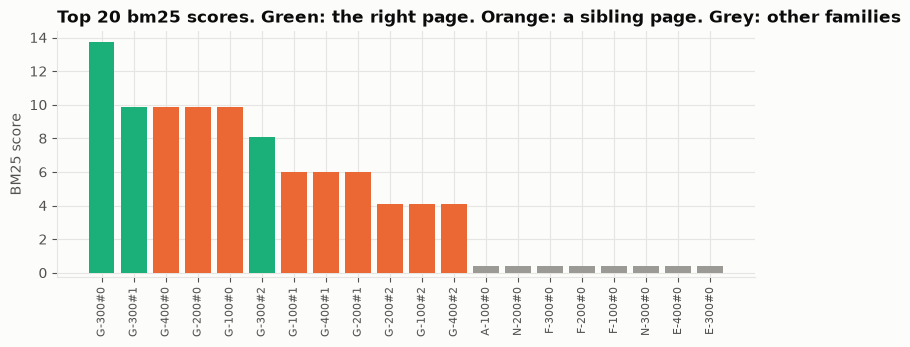

In [17]:
method = "dense" if EMB else "bm25"
scores = INDEX.scores(q["question"], method)
order = np.argsort(-scores)[:20]
cols = ["#1baf7a" if CHUNKS[i]["doc_id"] == q["doc_id"] else ("#eb6834" if CHUNKS[i]["doc_id"][0] == q["doc_id"][0] else "#9b9a95") for i in order]
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(range(20), scores[order], color=cols)
ax.set_xticks(range(20)); ax.set_xticklabels([CHUNKS[i]["chunk_id"] for i in order], rotation=90, fontsize=8)
pad = 0.05 * (scores[order].max() - scores[order].min() + 1e-9)
ax.set_ylim(scores[order].min() - pad, scores[order].max() + pad); ax.set_ylabel("cosine similarity" if EMB else "BM25 score")
ax.set_title(f"Top 20 {method} scores. Green: the right page. Orange: a sibling page. Grey: other families")
plt.show()

## 4. Retrieval on its own: chunk size, title in every chunk, method

Before any LLM, measure retrieval directly. **hit@k** = share of the 200 test questions where a chunk from the right page that contains the answer is in the top k. This needs only the embedding model, so it takes about a minute.

In [18]:
# with no GPU this sweeps BM25 only and saves nothing
sweep = run_rag_bench.retrieval_sweep(EMB, Path(RESULTS) / "retrieval.json" if EMB else None)

       32 words, header False bm25    hit@1 28%  hit@3 50%  hit@5 59%  hit@10 97%  MRR 0.43


       32 words, header True  bm25    hit@1 34%  hit@3 97%  hit@5 100%  hit@10 100%  MRR 0.58


       64 words, header False bm25    hit@1 55%  hit@3 100%  hit@5 100%  hit@10 100%  MRR 0.70


       64 words, header True  bm25    hit@1 56%  hit@3 100%  hit@5 100%  hit@10 100%  MRR 0.71


      128 words, header False bm25    hit@1 74%  hit@3 100%  hit@5 100%  hit@10 100%  MRR 0.87


      128 words, header True  bm25    hit@1 83%  hit@3 100%  hit@5 100%  hit@10 100%  MRR 0.92
whole doc words, header False bm25    hit@1 100%  hit@3 100%  hit@5 100%  hit@10 100%  MRR 1.00
whole doc words, header True  bm25    hit@1 100%  hit@3 100%  hit@5 100%  hit@10 100%  MRR 1.00


In [19]:
sw = pd.DataFrame(sweep)
sw.pivot_table(index=["chunk_words", "header"], columns="method", values="hit@3").style.format("{:.0%}").background_gradient(cmap="Blues", vmin=0, vmax=1)

In [20]:
figures.RES = Path("results")
figures.OUT = Path(RESULTS) / "figures" if ON_COLAB else Path("results/figures")   # locally: the committed figures
if ON_COLAB:
    figures.week7_retrieval_sweep()
fig_path = figures.OUT / "week7_retrieval_sweep.png"
display(Image(str(fig_path))) if fig_path.exists() else print("This figure appears after the GPU run.")

This figure appears after the GPU run.


The main pipeline stays at 64-word chunks, no title, dense, k = 3, as fixed in the plan. The sweep is exploratory: it shows what the fixed choice costs or gains, it does not pick the configuration after seeing the test questions.

## 5. Generation: from chunks to a prompt to an answer

The retrieved chunks go into the prompt, best first, numbered. The model is told to reply with the bare answer, or `unknown` if the context does not say.

In [21]:
show(rag.messages)

def messages(question: str, passages: list[str] | None) -> list[dict]:
    """Closed-book when passages is None; otherwise numbered passages, best first, then the question."""
    if passages is None:
        return [{"role": "system", "content": SYSTEM_CLOSED}, {"role": "user", "content": question}]
    ctx = "\n\n".join(f"[{i}] {p}" for i, p in enumerate(passages, 1))
    return [{"role": "system", "content": SYSTEM_RAG},
            {"role": "user", "content": f"Context:\n{ctx}\n\nQuestion: {question}"}]

In [22]:
pipe = run_rag_bench.Pipeline("test", 200, EMB)
passages, hits = pipe.passages("dense_k3" if EMB else "bm25_k3", q)
for m in rag.messages(q["question"], passages):
    print(f"── {m['role']} ──\n{m['content']}\n")

── system ──
You answer questions about products using only the context below. Reply with only the answer: a number or a short phrase, not a sentence. If the context does not contain the answer, reply: unknown

── user ──
Context:
[1] The Galen G-300 is a power bank made by Galen. It was first released in 2022 and is assembled at the Galen works in Larkmoor. Like the rest of the Galen G-series, it is designed for long trips off the grid and ships with a printed quick-start guide and a two-year supply of consumables where these apply. Galen builds every G-series power bank around

[2] and a two-year supply of consumables where these apply. Galen builds every G-series power bank around a modular frame, so worn parts can be replaced at home with ordinary tools. The G-300 weighs 21.3 kg and is rated at 550 W. It comes in mustard yellow only, and the finish is tested against scratches and fading in direct sunlight. Spare parts and service manuals

[3] The Galen G-100 is a power bank made by

Scoring reads the reply as a number (or one named colour or town) and compares it with the gold value. It also flags replies that give a **sibling product's** value, the typical distractor error:

In [23]:
show(rag.parse_answer)
for reply in ["550 W", "The G-300 is rated at 550 W.", "505", "unknown"]:
    print(f"{reply!r:35} → {rag.parse_answer(reply, q)}")

def parse_answer(text: str, q: dict) -> dict:
    """The predicted value, whether the model abstained, and whether it gave a sibling's value."""
    from rag_corpus import CHOICES
    t = text.strip().lower()
    abstained = t.startswith("unknown") or "not contain" in t or "does not say" in t
    code = q["doc_id"].lower()                                   # "C-200 weighs 3.4 kg": drop the code first
    t_num = t.replace(q["name"].lower(), " ").replace(code, " ")
    if q["kind"] == "number":
        m = NUM.search(t_num)
        pred = float(m.group().replace(",", "")) if m else None
        same = lambda v: pred is not None and abs(pred - float(v)) < 1e-6   # noqa: E731
    else:
        named = [c for c in CHOICES[q["attribute"]] if c.lower() in t]
        pred = named[0] if len(named) == 1 else (None if not named else "|".join(named))
        same = lambda v: pred == v   # noqa: E731
    return dict(pred=pred, abstained=abstained and pred is None, correct=same(q["gold"]),
                sibling=any(same(v) for v in q["sibling_values"]),
                stale=same(q["old_gold"]) if q.get("old_gold", q["gold"]) != q["gold"] else False)

'550 W'                             → {'pred': 550.0, 'abstained': False, 'correct': True, 'sibling': False, 'stale': False}
'The G-300 is rated at 550 W.'      → {'pred': 550.0, 'abstained': False, 'correct': True, 'sibling': False, 'stale': False}
'505'                               → {'pred': 505.0, 'abstained': False, 'correct': False, 'sibling': True, 'stale': False}
'unknown'                           → {'pred': None, 'abstained': True, 'correct': False, 'sibling': False, 'stale': False}


## 6. Checks before the long run

The model-free tests first: corpus, chunking, BM25, scoring, and a full run with a fake model. Then the **dev gate** from the plan: 24 dev questions (different brands from the test set) on the 1.5B model. If the oracle scores below 50% here, stop: the test run would be meaningless.

In [24]:
!{sys.executable} tests/test_week7.py 2>&1 | grep -E '^ok|passed|Error|assert'

ok  test_corpus
ok  test_chunking
ok  test_bm25_and_index
ok  test_scoring


ok  test_run_and_summary
all Week 7 checks passed


In [25]:
llm = None
dev_path = Path(RESULTS) / "dev" / "Qwen2.5-1.5B-Instruct.jsonl"
if GPU:
    from run_prompt_bench import BatchLLM
    llm = BatchLLM("Qwen/Qwen2.5-1.5B-Instruct")
    run_rag_bench.run("Qwen/Qwen2.5-1.5B-Instruct", ["closed", "dense_k3", "oracle"], "dev", 24, dev_path, 24, llm=llm, embedder=EMB)
    dev = pd.DataFrame(run_rag_bench.table([dev_path]))
    display(dev[["condition", "n", "accuracy", "abstained", "answer_retrieved"]])
    oracle_dev = dev.set_index("condition").loc["oracle", "accuracy"]
    assert oracle_dev >= 0.5, f"dev gate failed: oracle {oracle_dev:.0%} < 50%. Stop and record why before the test run."
    print(f"dev gate passed: oracle {oracle_dev:.0%}")
else:
    print("No GPU: the dev gate runs on Colab before the test run.")

No GPU: the dev gate runs on Colab before the test run.


A few dev answers, to see what the model actually writes:

In [26]:
if dev_path.exists():
    display(pd.read_json(dev_path, lines=True)[["condition", "question", "gold", "output", "correct"]].sample(8, random_state=0))
else:
    print("No dev answers yet.")

No dev answers yet.


## 7. The test run

Both models, all 9 conditions, the same 200 questions. Each model is loaded once.

In [27]:
pd.DataFrame([{"condition": k, "retrieval": v[0] or "none", "k": v[1], "corpus edition": v[2]} for k, v in run_rag_bench.CONDITIONS.items()])

,condition,retrieval,k,corpus edition
0,closed,none,0,1
1,oracle,oracle,1,1
2,dense_k1,dense,1,1
3,dense_k3,dense,3,1
4,dense_k5,dense,5,1
5,dense_k10,dense,10,1
6,bm25_k3,bm25,3,1
7,hybrid_k3,hybrid,3,1
8,swap_dense_k3,dense,3,2


In [28]:
import gc
MODELS = ["Qwen/Qwen2.5-1.5B-Instruct", "Qwen/Qwen2.5-3B-Instruct"]
if GPU:
    for model in MODELS:
        if llm is None or llm.name != model:
            llm = None; gc.collect(); torch.cuda.empty_cache()
            llm = BatchLLM(model)
        run_rag_bench.run(model, list(run_rag_bench.CONDITIONS), "test", 200,
                          Path(RESULTS) / f"{model.split('/')[-1]}.jsonl", 16, llm=llm, pipe=pipe)
PATHS = [p for p in (Path(RESULTS) / f"{m.split('/')[-1]}.jsonl" for m in MODELS) if p.exists()]
print("result files:", [str(p) for p in PATHS] or "none yet: the test run is pending")

result files: none yet: the test run is pending


## 8. Results

The full printout first (it is also what the notes are written from), then the same numbers as tables.

In [29]:
RES = run_rag_bench.summary(PATHS) if PATHS else print('Results appear here after the test run.')

Results appear here after the test run.


In [30]:
if not PATHS:
    print("Pending the test run.")
else:
    t = pd.DataFrame(RES["_table"])
    t["95% CI"] = t.apply(lambda r: f"{r.ci_lo:.0%} to {r.ci_hi:.0%}", axis=1)
    display(t[["model", "condition", "accuracy", "95% CI", "abstained", "sibling_answer", "answer_retrieved", "tokens_in"]]
            .style.format({"accuracy": "{:.1%}", "abstained": "{:.1%}", "sibling_answer": "{:.1%}", "answer_retrieved": "{:.1%}", "tokens_in": "{:.0f}"}, na_rep="")
            .bar(subset=["accuracy"], color="#9ec5f0", vmin=0, vmax=1))

Pending the test run.


### Confirmatory: H1 (RAG vs closed-book) and H2 (RAG vs oracle)

In [31]:
if not PATHS:
    print("Pending the test run.")
else:
    rows = []
    for model, r in RES.items():
        if model.startswith("_"): continue
        if "h1" in r:
            h = r["h1"]; rows.append(dict(model=model, hypothesis="H1: dense_k3 − closed", effect=f"{h['effect']*100:+.1f}",
                CI=f"{h['lo']*100:+.1f} to {h['hi']*100:+.1f}", discordant=h["discordant"], holm_p=f"{h['p_holm']:.2g}",
                verdict="supported" if h["supported"] else "not supported"))
        if "h2" in r:
            h = r["h2"]; rows.append(dict(model=model, hypothesis="H2: dense_k3 − oracle (±5)", effect=f"{h['effect']*100:+.1f}",
                CI=f"{h['lo']*100:+.1f} to {h['hi']*100:+.1f}", discordant=h["discordant"], holm_p="", verdict=h["verdict"]))
    display(pd.DataFrame(rows))

Pending the test run.


### Figures

In [32]:
if ON_COLAB and PATHS:
    for fn in (figures.week7_accuracy_by_condition, figures.week7_topk, figures.week7_failures):
        fn()
for name in ("week7_accuracy_by_condition", "week7_topk", "week7_failures"):
    f = figures.OUT / f"{name}.png"
    display(Image(str(f))) if f.exists() else print(f"{name}: appears after the test run.")

week7_accuracy_by_condition: appears after the test run.
week7_topk: appears after the test run.
week7_failures: appears after the test run.


## 9. Looking at the failures

Numbers say how often; examples say why. Below: questions the main pipeline got wrong, with what was retrieved and what the model said.

In [33]:
if not PATHS:
    print("Pending the test run.")
else:
    def explain(r):
        print(f"Q{r['qid']}: {r['question']}\n   gold {r['gold']!r}, model said {r['output']!r}"
              f"  (sibling value: {r['sibling']}, answer chunk rank: {r['gold_rank']})")
        for cid in r["retrieved"]:
            c = next(x for x in pipe.index(1).chunks if x["chunk_id"] == cid)
            print(f"     [{cid}] {c['text'][:150]}…")
        print()

    big = PATHS[-1]
    for kind in ("miss", "sibling"):
        display(Markdown(f"**{kind}**: " + {"miss": "the answer chunk was not retrieved", "sibling": "the model gave another product's value"}[kind]))
        for r in run_rag_bench.examples(big, kind=kind, n=3):
            explain(r)

Pending the test run.


Accuracy by fact, main pipeline:

In [34]:
if not PATHS:
    print("Pending the test run.")
else:
    display(pd.DataFrame({m: {a: f"{c}/{n}" for a, (c, n) in r["failures"]["accuracy_by_attribute"].items()}
                          for m, r in RES.items() if not m.startswith("_") and "failures" in r}))

Pending the test run.


### The index swap (Lewis et al. claim 2)

Same questions, same model, but the index now holds edition 2 of every page. Did the answers follow the new documents?

In [35]:
if not PATHS:
    print("Pending the test run.")
else:
    swap = pd.read_json(big, lines=True)
    swap = swap[swap.condition == "swap_dense_k3"]
    display(pd.DataFrame({"correct (new value)": [swap.correct.mean()], "stale (old value)": [swap.stale.mean()],
                          "said unknown": [swap.abstained.mean()]}).style.format("{:.1%}"))

Pending the test run.


## 10. Save and download

The zip holds the raw results, the retrieval sweep, the figures and a copy of this notebook **with its outputs**. Unzip it into `results/` in the repo.

In [36]:
if not ON_COLAB:
    print("Local run: nothing to save or download.")
else:
  try:   # save this notebook with every output, so the results and graphs are readable on GitHub
    from google.colab import _message
    nb = _message.blocking_request("get_ipynb", timeout_sec=60)["ipynb"]
    with open(os.path.join(RESULTS, "week7_rag_colab_executed.ipynb"), "w") as f:
        json.dump(nb, f)
    print("saved the executed notebook")
  except Exception as e:
    print("could not save the executed notebook:", e, "\nUse File → Download → Download .ipynb instead.")

Local run: nothing to save or download.


In [37]:
if ON_COLAB:
    zip_path = os.path.join(BASE, "week7_results.zip")
    !cd results && zip -qr {zip_path} week7/
    from google.colab import files
    files.download(zip_path)